In [1]:
!nvidia-smi

Fri Oct  9 06:51:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Prev

In [3]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [2]:
# %load_ext cudf.pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# %%time
# path = '/content/drive/MyDrive/lending-club/accepted_2007_to_2018Q4.csv'
path = 'accepted_2007_to_2018Q4.csv'
df = pd.read_csv(path, low_memory=False)
df.shape

(2260701, 151)

In [6]:
# Memory check: GPU and RAM headroom after loading
# !nvidia-smi --query-gpu=memory.used,memory.total --format=csv
# !free -h

memory.used [MiB], memory.total [MiB]
6383 MiB, 15360 MiB
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.8Gi       4.6Gi       140Mi       6.7Gi        10Gi
Swap:             0B          0B          0B


prints a table showing which calls ran on the GPU and which fell back to the CPU.

In [2]:
# %%cudf.pandas.profile
# df.groupby('loan_status')['loan_amnt'].mean()

UsageError: Cell magic `%%cudf.pandas.profile` not found.


In [6]:
# Show all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

In [7]:
# Shape: rows and columns
df.shape

(2260701, 151)

In [8]:
# First rows
display(df.head(5))

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,30.0,NaN,7.0,0.0,2765.0,29.7,13.0,w,0.00,0.00,4421.723917,4421.72,3600.00,821.72,0.0,0.0,0.0,Jan-2019,122.67,NaN,Mar-2019,564.0,560.0,0.0,30.0,1.0,Individual,NaN,NaN,NaN,0.0,722.0,144904.0,2.0,2.0,0.0,1.0,21.0,4981.0,36.0,3.0,3.0,722.0,34.0,9300.0,3.0,1.0,4.0,4.0,20701.0,1506.0,37.2,0.0,0.0,148.0,128.0,3.0,3.0,1.0,4.0,69.0,4.0,69.0,2.0,2.0,4.0,2.0,5.0,3.0,4.0,9.0,4.0,7.0,0.0,0.0,0.0,3.0,76.9,0.0,0.0,0.0,178050.0,7746.0,2400.0,13734.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,6.0,NaN,22.0,0.0,21470.0,19.2,38.0,w,0.00,0.00,25679.660000,25679.66,24700.00,979.66,0.0,0.0,0.0,Jun-2016,926.35,NaN,Mar-2019,699.0,695.0,0.0,NaN,1.0,Individual,NaN,NaN,NaN,0.0,0.0,204396.0,1.0,1.0,0.0,1.0,19.0,18005.0,73.0,2.0,3.0,6472.0,29.0,111800.0,0.0,0.0,6.0,4.0,9733.0,57830.0,27.1,0.0,0.0,113.0,192.0,2.0,2.0,4.0,2.0,NaN,0.0,6.0,0.0,5.0,5.0,13.0,17.0,6.0,20.0,27.0,5.0,22.0,0.0,0.0,0.0,2.0,97.4,7.7,0.0,0.0,314017.0,39475.0,79300.0,24667.0,NaN,NaN,NaN,NaN,NaN,N

In [9]:
# Last rows
display(df.tail(5))

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
2260696,88985880,NaN,40000.0,40000.0,40000.0,60 months,10.49,859.56,B,B3,Vice President,9 years,MORTGAGE,227000.0,Verified,Oct-2016,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,NaN,907xx,CA,12.75,7.0,Feb-1995,705.0,709.0,1.0,9.0,NaN,5.0,0.0,8633.0,64.9,37.0,f,23252.59,23252.59,24903.93,24903.93,16747.41,8156.52,0.00,0.0,0.0,Mar-2019,859.56,Apr-2019,Mar-2019,724.0,720.0,0.0,10.0,1.0,Individual,NaN,NaN,NaN,0.0,0.0,28398.0,0.0,2.0,0.0,1.0,15.0,19765.0,46.0,0.0,0.0,5141.0,51.0,13300.0,3.0,0.0,2.0,2.0,5680.0,4070.0,66.9,0.0,0.0,154.0,258.0,33.0,15.0,3.0,41.0,9.0,1.0,9.0,6.0,2.0,3.0,2.0,15.0,9.0,3.0,23.0,3.0,5.0,0.0,0.0,7.0,0.0,75.7,50.0,0.0,0.0,55970.0,28398.0,12300.0,42670.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2260697,88224441,NaN,24000.0,24000.0,24000.0,60 months,14.49,564.56,C,C4,Program Manager,6 years,RENT,110000.0,Not Verified,Oct-2016,Charged Off,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,334xx,FL,18.30,0.0,Jul-1999,660.0,664.0,0.0,67.0,72.0,10.0,1.0,17641.0,68.1,31.0,f,0.00,0.00,6755.40,6755.40,3521.91,3233.49,0.00,0.0,0.0,Oct-2017,564.56,NaN,Mar-2019,594.0,590.0,0.0,67.0,1.0,Individual,NaN,NaN,NaN,0.0,0.0,62426.0,0.0,2.0,0.0,2.0,20.0,44785.0,78.0,1.0,5.0,6172.0,73.0,25900.0,0.0,0.0,1.0,7.0,6243.0,4660.0,77.5,0.0,0.0,132.0,206.0,9.0,9.0,2.0,9.0,NaN,9.0,NaN,1.0,5.0,7.0,5.0,15.0,4.0,8.0,24.0,7.0,10.0,0.0,0.0,0.0,1.0,96.2,40.0,1.0,0.0,84664.0,62426.0,20700.0,58

In [10]:
# Types and non-null counts for all columns
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Data columns (total 151 columns):
 #    Column                                      Non-Null Count    Dtype  
---   ------                                      --------------    -----  
 0    id                                          2260701 non-null  str    
 1    member_id                                   0 non-null        float64
 2    loan_amnt                                   2260668 non-null  float64
 3    funded_amnt                                 2260668 non-null  float64
 4    funded_amnt_inv                             2260668 non-null  float64
 5    term                                        2260668 non-null  str    
 6    int_rate                                    2260668 non-null  float64
 7    installment                                 2260668 non-null  float64
 8    grade                                       2260668 non-null  str    
 9    sub_grade                                   2260668 non

In [11]:
# Summary of the numeric columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
member_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,2260668.0,15046.931228,9190.245488,5.000000e+02,8000.0000,12900.000,20000.000000,4.000000e+04
funded_amnt,2260668.0,15041.664057,9188.413022,5.000000e+02,8000.0000,12875.000,20000.000000,4.000000e+04
funded_amnt_inv,2260668.0,15023.437745,9192.331679,0.000000e+00,8000.0000,12800.000,20000.000000,4.000000e+04
int_rate,2260668.0,13.092829,4.832138,5.310000e+00,9.4900,12.620,15.990000,3.099000e+01
installment,2260668.0,445.806823,267.173535,4.930000e+00,251.6500,377.990,593.320000,1.719830e+03
annual_inc,2260664.0,77992.428687,112696.199574,0.000000e+00,46000.0000,65000.000,93000.000000,1.100000e+08
dti,2258957.0,18.824196,14.183329,-1.000000e+00,11.8900,17.840,24.490000,9.990000e+02
delinq_2yrs,2260639.0,0.306879,0.867230,0.000000e+00,0.0000,0.000,0.000000,5.800000e+01
fico_range_low,2260668.0,698.588205,33.010376,6.100000e+02,675.0000,690.000,715.000000,8.450000e+02


In [12]:
# Does describe() match what should be numeric?
num_cols = df.select_dtypes(include='number').columns
text_cols = df.select_dtypes(exclude='number').columns

In [13]:
print('Total columns:  ', df.shape[1])
print('Numeric columns:', len(num_cols))
print('Text columns:   ', len(text_cols))
print('describe() rows:', df.describe().shape[1])
print()
print(list(text_cols))

Total columns:   151
Numeric columns: 113
Text columns:    38
describe() rows: 113

['id', 'term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d', 'application_type', 'verification_status_joint', 'sec_app_earliest_cr_line', 'hardship_flag', 'hardship_type', 'hardship_reason', 'hardship_status', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'hardship_loan_status', 'disbursement_method', 'debt_settlement_flag', 'debt_settlement_flag_date', 'settlement_status', 'settlement_date']


In [14]:
# One sample value from each text column
display(df[text_cols].head(3).T)

,0,1,2
id,68407277,68355089,68341763
term,36 months,36 months,60 months
grade,C,C,B
sub_grade,C4,C1,B4
emp_title,leadman,Engineer,truck driver
emp_length,10+ years,10+ years,10+ years
home_ownership,MORTGAGE,MORTGAGE,MORTGAGE
verification_status,Not Verified,Not Verified,Not Verified
issue_d,Dec-2015,Dec-2015,Dec-2015
loan_status,Fully Paid,Fully Paid,Fully Paid


In [23]:
# Stage 1, Step 2 - Check 1: junk rows
# Every real loan has a loan amount, so rows without one are not loans
junk_rows = df[df['loan_amnt'].isna()]
print('Junk rows:', len(junk_rows))

# Which columns hold any value at all in these rows
print('Columns with a value:', junk_rows.columns[junk_rows.notna().any()].tolist())

# What these rows contain in the id column
display(junk_rows['id'])

Junk rows: 33
Columns with a value: ['id']


421095     Total amount funded in policy code 1: 6417608175
421096     Total amount funded in policy code 2: 1944088810
528961     Total amount funded in policy code 1: 1741781700
528962      Total amount funded in policy code 2: 564202131
651664     Total amount funded in policy code 1: 1791201400
651665      Total amount funded in policy code 2: 651669342
749520     Total amount funded in policy code 1: 1443412975
749521      Total amount funded in policy code 2: 511988838
877716     Total amount funded in policy code 1: 2063142975
877717      Total amount funded in policy code 2: 823319310
983169     Total amount funded in policy code 1: 1538432075
983170      Total amount funded in policy code 2: 608903141
1117058    Total amount funded in policy code 1: 2087217200
1117059     Total amount funded in policy code 2: 662815446
1352689    Total amount funded in policy code 1: 3503840175
1352690     Total amount funded in policy code 2: 873652739
1481103    Total amount funded in policy

In [24]:
# Stage 1, Step 2 - Check 2: columns that carry no information
# Count distinct values in every column (missing values are not counted)
n_unique = df.nunique()

# Columns that are completely empty or hold only one value
no_info = n_unique[n_unique <= 1]
print('Columns with one value or none:')
print(no_info)

# Pure identifiers: a different value on every row
print()
print('Real loans:', df['loan_amnt'].notna().sum())
print(n_unique[['id', 'url']])

Columns with one value or none:
member_id          0
policy_code        1
hardship_type      1
deferral_term      1
hardship_length    1
dtype: int64

Real loans: 2260668
id     2260701
url    2260668
dtype: int64


In [25]:
# Stage 1, Step 2 - Check 3: duplicates
# Repeated loan ids
print('Repeated ids:', df['id'].duplicated().sum())

# Fully identical rows once the identifier columns are left out
# (an ID column makes every row look unique, so the check could never fail with it in)
cols_no_id = df.columns.drop(['id', 'url'])
dup_mask = df.duplicated(subset=cols_no_id) & df['loan_amnt'].notna()
print('Identical loans (ignoring id and url):', dup_mask.sum())

Repeated ids: 0
Identical loans (ignoring id and url): 0


In [26]:
# Stage 1, Step 2 - Check 4: numbers and dates stored as text
# term: a number of months stored with the word "months"
print(df['term'].value_counts(dropna=False))
print()

# emp_length: years of employment stored as text
print(df['emp_length'].value_counts(dropna=False))
print()

# Date columns stored as text: distinct values, values not in Mon-YYYY form, and examples
date_cols = ['issue_d', 'earliest_cr_line', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d']
for col in date_cols:
    values = df[col].dropna()
    bad_format = (~values.str.match('^[A-Z][a-z]{2}-[0-9]{4}$')).sum()
    print(col, '| distinct:', values.nunique(), '| not Mon-YYYY:', bad_format, '| examples:', values.unique()[:5].tolist())

term
 36 months    1609754
 60 months     650914
NaN                33
Name: count, dtype: int64

emp_length
10+ years    748005
2 years      203677
< 1 year     189988
3 years      180753
1 year       148403
NaN          146940
5 years      139698
4 years      136605
6 years      102628
7 years       92695
8 years       91914
9 years       79395
Name: count, dtype: int64

issue_d | distinct: 139 | not Mon-YYYY: 0 | examples: ['Dec-2015', 'Nov-2015', 'Oct-2015', 'Sep-2015', 'Aug-2015']
earliest_cr_line | distinct: 754 | not Mon-YYYY: 0 | examples: ['Aug-2003', 'Dec-1999', 'Aug-2000', 'Sep-2008', 'Jun-1998']
last_pymnt_d | distinct: 136 | not Mon-YYYY: 0 | examples: ['Jan-2019', 'Jun-2016', 'Jun-2017', 'Feb-2019', 'Jul-2016']
next_pymnt_d | distinct: 106 | not Mon-YYYY: 0 | examples: ['Apr-2019', 'Mar-2019', 'Dec-2018', 'Sep-2018', 'May-2019']
last_credit_pull_d | distinct: 141 | not Mon-YYYY: 0 | examples: ['Mar-2019', 'Mar-2018', 'May-2017', 'Nov-2018', 'Sep-2018']


In [27]:
# Stage 1, Step 2 - Check 5: disguised missing values in text columns
# List every value of the small categorical columns to spot stand-ins for "missing"
cat_cols = ['home_ownership', 'verification_status', 'purpose', 'application_type']
for col in cat_cols:
    print(df[col].value_counts(dropna=False))
    print()

# Search every text column for common stand-in strings
placeholders = ['n/a', 'na', 'none', 'null', 'unknown', 'any', 'other', '?', '-', '']
for col in text_cols:
    hits = df[col].str.strip().str.lower().isin(placeholders).sum()
    if hits > 0:
        print(col, '| stand-in values:', hits)

home_ownership
MORTGAGE    1111450
RENT         894929
OWN          253057
ANY             996
OTHER           182
NONE             54
NaN              33
Name: count, dtype: int64

verification_status
Source Verified    886231
Not Verified       744806
Verified           629631
NaN                    33
Name: count, dtype: int64

purpose
debt_consolidation    1277877
credit_card            516971
home_improvement       150457
other                  139440
major_purchase          50445
medical                 27488
small_business          24689
car                     24013
vacation                15525
moving                  15403
house                   14136
wedding                  2355
renewable_energy         1445
educational               424
NaN                        33
Name: count, dtype: int64

application_type
Individual    2139958
Joint App      120710
NaN                33
Name: count, dtype: int64

emp_title | stand-in values: 19
home_ownership | stand-in values: 1232
d

In [28]:
# Stage 1, Step 2 - Check 6: disguised missing values and impossible numbers
# Exact counts of suspicious values in key columns
print('dti == -1:        ', (df['dti'] == -1).sum())
print('dti == 999:       ', (df['dti'] == 999).sum())
print('dti < 0:          ', (df['dti'] < 0).sum())
print('dti > 100:        ', (df['dti'] > 100).sum())
print('annual_inc == 0:  ', (df['annual_inc'] == 0).sum())
print('revol_util > 100: ', (df['revol_util'] > 100).sum())
print()

# Reported versus true missing rate for dti, once -1 and 999 are counted as missing
reported = df['dti'].isna().mean() * 100
true_rate = (df['dti'].isna() | df['dti'].isin([-1, 999])).mean() * 100
print('dti missing, reported: %.3f%% | true: %.3f%%' % (reported, true_rate))

# Scan every numeric column for negative values and placeholder-style values
sentinels = [-1, 999, 9999, 99999, 999999]
rows = {}
for col in num_cols:
    s = df[col]
    rows[col] = {'min': s.min(), 'max': s.max(), 'negatives': (s < 0).sum(), 'sentinels': s.isin(sentinels).sum()}
scan = pd.DataFrame(rows).T
display(scan[(scan['negatives'] > 0) | (scan['sentinels'] > 0)])

dti == -1:         2
dti == 999:        135
dti < 0:           2
dti > 100:         2561
annual_inc == 0:   1667
revol_util > 100:  7343

dti missing, reported: 0.077% | true: 0.083%


,min,max,negatives,sentinels
annual_inc,0.000000e+00,1.100000e+08,0.0,46.0
dti,-1.000000e+00,9.990000e+02,2.0,137.0
revol_bal,0.000000e+00,2.904836e+06,0.0,182.0
total_pymnt,0.000000e+00,6.329688e+04,0.0,2.0
total_pymnt_inv,0.000000e+00,6.329688e+04,0.0,2.0
total_rec_prncp,0.000000e+00,4.000000e+04,0.0,2.0
total_rec_int,0.000000e+00,2.819250e+04,0.0,8.0
total_rec_late_fee,-9.500000e-09,1.484340e+03,8.0,0.0
recoveries,0.000000e+00,3.985955e+04,0.0,1.0
collection_recovery_fee,0.000000e+00,7.174719e+03,0.0,1.0


## Stage 1, Step 2: What is broken?

### Problem list

| # | Column or issue | What is wrong | Rows affected | Proposed fix |
|---|---|---|---|---|
| 1 | Junk rows | Not loans; only `id` holds a value | 33 | Drop the rows |
| 2 | `id` | Stored as text because of the junk rows; pure identifier | all | Drop the column after removing junk rows |
| 3 | `url` | Pure identifier, one distinct value per loan | all | Drop the column |
| 4 | `member_id` | Completely empty | all | Drop the column |
| 5 | `policy_code` | One value only | all | Drop the column |
| 6 | `hardship_type`, `deferral_term`, `hardship_length` | One value only | all | Drop the columns |
| 7 | `term` | Number stored as text, with a leading space | all | Strip and convert to 36 or 60 |
| 8 | `emp_length` | Number stored as text (`10+ years`, `< 1 year`) | all | Convert to a number |
| 9 | `emp_length` | Missing | 146,907 loans (6.5%) | 5-30% band: impute carefully or keep as its own category |
| 10 | `issue_d`, `earliest_cr_line`, `last_pymnt_d`, `next_pymnt_d`, `last_credit_pull_d` | Dates stored as text, all in `Mon-YYYY` form | all | Convert to dates |
| 11 | `home_ownership` | Stand-in categories: ANY 996, OTHER 182, NONE 54 | 1,232 | Merge into one group or treat as missing |
| 12 | `dti` | Placeholder values: 999 (135 rows) and -1 (2 rows) | 137 | Treat as missing |
| 13 | `dti` | Above 100, implausible for a debt-to-income ratio | 2,561 | Judgment call: cap or treat as missing |
| 14 | `annual_inc` | Zero income | 1,667 | Judgment call: check whether these are joint applications |
| 15 | `annual_inc` | Maximum of $110 million | few | Entry error versus real extreme; handle in the outlier step |
| 16 | `revol_util` | Above 100% | 7,343 | Probably real (over the credit limit); keep or cap |
| 17 | `mo_sin_old_il_acct`, `mo_sin_old_rev_tl_op` | Maximum of 999 months (83 years), looks like a placeholder | 3 | Treat as missing |
| 18 | `total_rev_hi_lim`, `tot_hi_cred_lim` | Maximum of 9,999,999, looks like a cap | not counted | Check how many sit at the cap |

### What came back clean

- **Duplicates:** 0 repeated ids and 0 identical loans once `id` and `url` are ignored.
- **Date formats:** 0 values outside the `Mon-YYYY` form in all five date columns.
- **`verification_status`, `purpose`, `application_type`:** no stand-in values. The "other" in `purpose` (139,440 loans) is a real category.

In [29]:
# Open decision 1: are dti > 100 and zero income linked, and are they joint applications?
high_dti = df['dti'] > 100
zero_inc = df['annual_inc'] == 0
print('dti > 100:      ', high_dti.sum())
print('annual_inc == 0:', zero_inc.sum())
print('Both together:  ', (high_dti & zero_inc).sum())
print()

# What dti looks like for the zero-income loans
print('Zero-income loans with dti missing:', df.loc[zero_inc, 'dti'].isna().sum())
print('Zero-income loans with dti == 999: ', (df.loc[zero_inc, 'dti'] == 999).sum())
print()

# Application type for each group
print('Zero income, by application type:')
print(df.loc[zero_inc, 'application_type'].value_counts())
print()
print('dti > 100, by application type:')
print(df.loc[high_dti, 'application_type'].value_counts())
print()

# Income of the loans with dti > 100
print('Annual income where dti > 100:')
print(df.loc[high_dti, 'annual_inc'].describe())
print()

# Open decision 2: home_ownership small groups - which years they come from and how the loans ended
small = df['home_ownership'].isin(['ANY', 'OTHER', 'NONE'])
print(pd.crosstab(df.loc[small, 'home_ownership'], df.loc[small, 'issue_d'].str[-4:]))
print()
print(pd.crosstab(df.loc[small, 'home_ownership'], df.loc[small, 'loan_status']))

dti > 100:       2561
annual_inc == 0: 1667
Both together:   0

Zero-income loans with dti missing: 1659
Zero-income loans with dti == 999:  0

Zero income, by application type:
application_type
Joint App    1667
Name: count, dtype: int64

dti > 100, by application type:
application_type
Joint App    2561
Name: count, dtype: int64

Annual income where dti > 100:
count     2561.000000
mean     11758.631538
std       9160.604924
min         15.000000
25%       5000.000000
50%      10000.000000
75%      15000.000000
max      72000.000000
Name: annual_inc, dtype: float64

issue_d         2007  2008  2009  2010  2011  2012  2014  2015  2016  2017  \
home_ownership                                                               
ANY                0     0     0     0     0     0     1     2   110   395   
NONE               7     1     0     0     0    42     0     0     0     4   
OTHER              0    47    85     3     1    46     0     0     0     0   

issue_d         2018  
home_owners

Columns with no missing values: 38
Under 5% missing:               50
5% to 30% missing:              5
Over 30% missing:               58


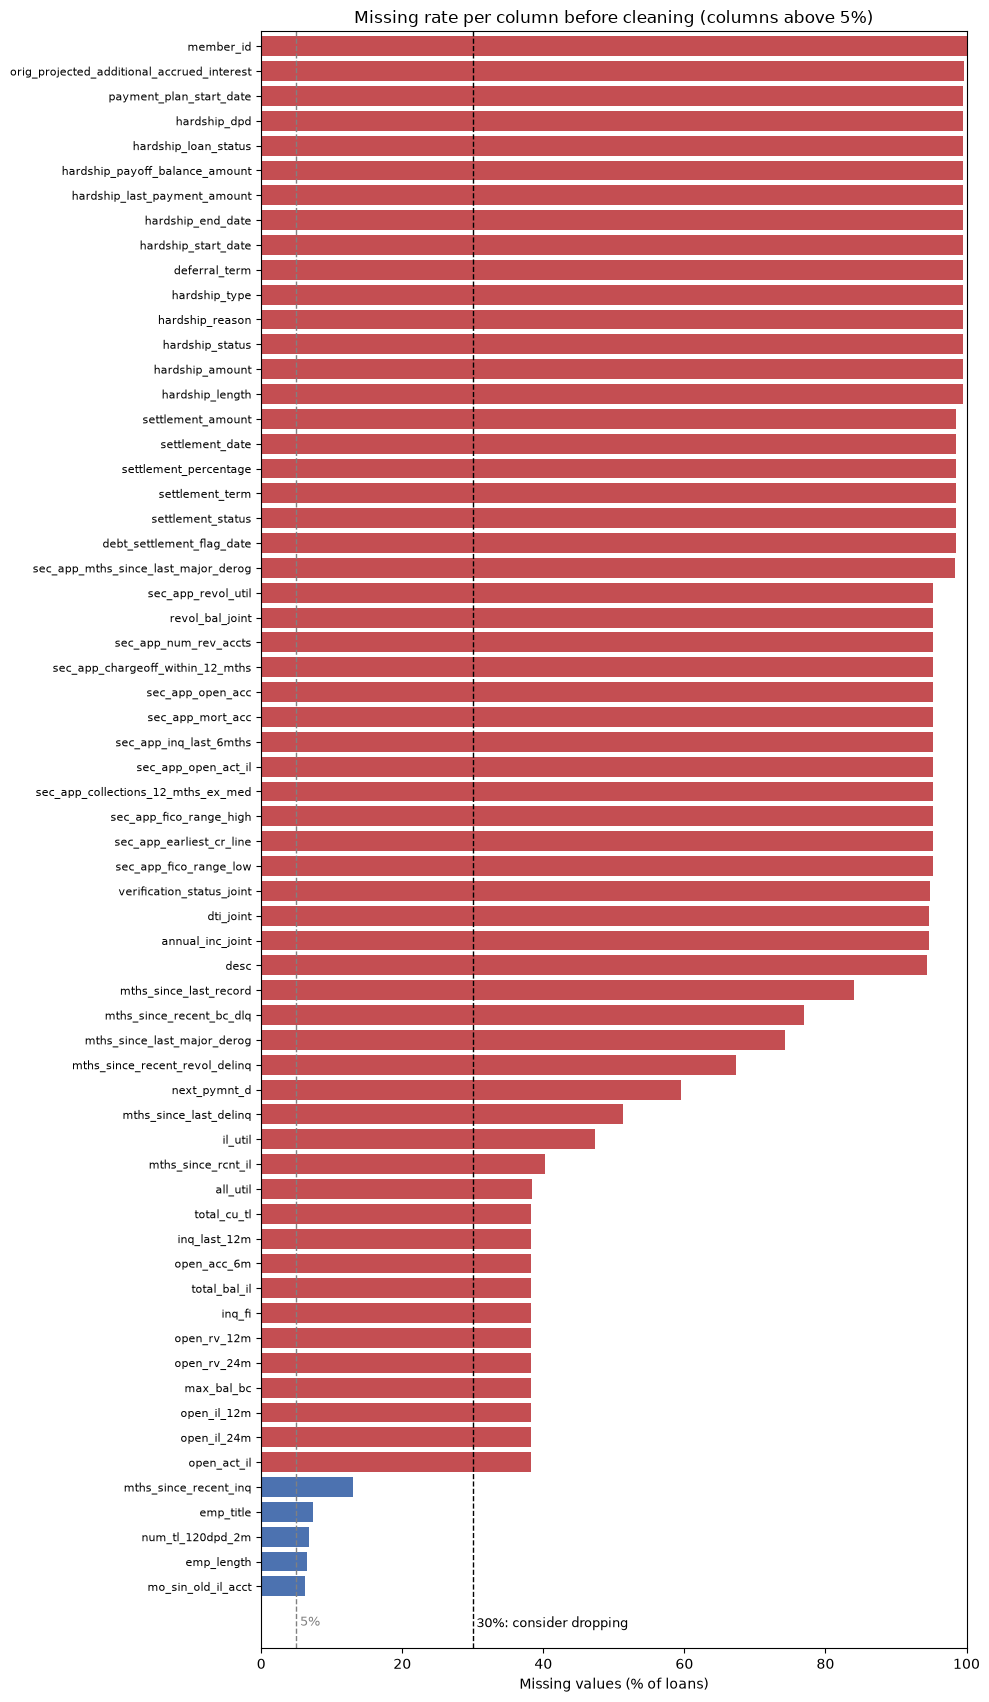

In [48]:
# Stage 1, Step 3 - Visual 1: missing rate per column (raw data, before cleaning)
# Question: which columns are too empty to use?
# Rates are computed on real loans only, so the 33 junk rows do not inflate them
real = df['loan_amnt'].notna()
missing_pct = df.isna()[real].mean() * 100

# How many columns fall in each of the lecture's bands
print('Columns with no missing values:', (missing_pct == 0).sum())
print('Under 5% missing:              ', ((missing_pct > 0) & (missing_pct < 5)).sum())
print('5% to 30% missing:             ', ((missing_pct >= 5) & (missing_pct <= 30)).sum())
print('Over 30% missing:              ', (missing_pct > 30).sum())

# Plot the columns above 5%, sorted, coloured by band
to_plot = missing_pct[missing_pct >= 5].sort_values()
colors = ['#c44e52' if v > 30 else '#4c72b0' for v in to_plot]

fig, ax = plt.subplots(figsize=(10, 0.24 * len(to_plot) + 2))
ax.barh(to_plot.index, to_plot.values, color=colors)
ax.axvline(5, color='grey', linestyle='--', linewidth=1)
ax.axvline(30, color='black', linestyle='--', linewidth=1)
ax.text(30.5, -1.2, '30%: consider dropping', fontsize=9, va='top')
ax.text(5.5, -1.2, '5%', fontsize=9, va='top', color='grey')
ax.set_xlim(0, 100)
ax.set_ylim(-2.5, len(to_plot) - 0.4)
ax.set_xlabel('Missing values (% of loans)')
ax.set_title('Missing rate per column before cleaning (columns above 5%)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

,count,min,max,mean
Other borrower and credit fields,5,6.2,13.1,8.0
Newer credit-bureau fields,14,38.3,47.3,39.1
Next payment date,1,59.5,59.5,59.5
Months since last delinquency or record,5,51.2,84.1,70.8
Second applicant and joint fields,16,94.7,98.4,95.3
Empty identifier and optional free text,2,94.4,100.0,97.2
Debt settlement fields,6,98.5,98.5,98.5
Hardship plan fields,14,99.5,99.6,99.5


open_acc_6m missing by issue year (%):
issue_d
2007    100.0
2008    100.0
2009    100.0
2010    100.0
2011    100.0
2012    100.0
2013    100.0
2014    100.0
2015     94.9
2016      0.0
2017      0.0
2018      0.0
Name: open_acc_6m, dtype: float64


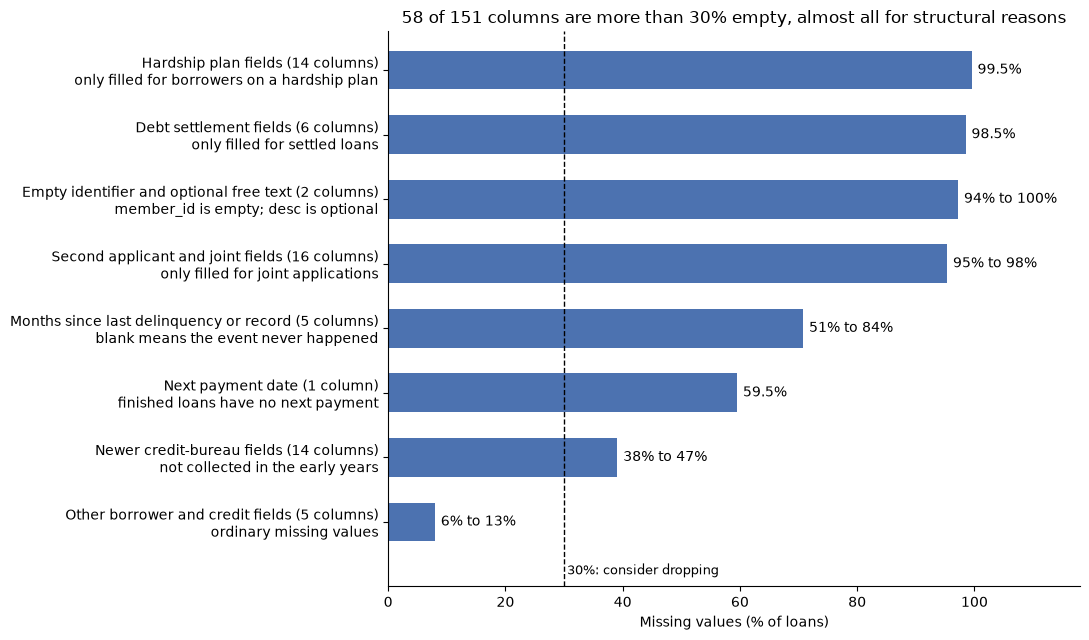

In [49]:
# Stage 1, Step 3 - Visual 1b: missing rate grouped by family of columns
# Question: why are the columns empty?
# Uses missing_pct from the cell above; each column above 5% is assigned to a family
def family(col):
    if col in ('member_id', 'desc'):
        return 'Empty identifier and optional free text'
    if col.startswith('hardship') or col in ('deferral_term', 'payment_plan_start_date', 'orig_projected_additional_accrued_interest'):
        return 'Hardship plan fields'
    if 'settlement' in col:
        return 'Debt settlement fields'
    if col.startswith('sec_app') or col.endswith('_joint'):
        return 'Second applicant and joint fields'
    if col in ('mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog',
               'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq'):
        return 'Months since last delinquency or record'
    if col == 'next_pymnt_d':
        return 'Next payment date'
    if col in ('open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util',
               'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m'):
        return 'Newer credit-bureau fields'
    return 'Other borrower and credit fields'

reasons = {
    'Empty identifier and optional free text': 'member_id is empty; desc is optional',
    'Hardship plan fields': 'only filled for borrowers on a hardship plan',
    'Debt settlement fields': 'only filled for settled loans',
    'Second applicant and joint fields': 'only filled for joint applications',
    'Months since last delinquency or record': 'blank means the event never happened',
    'Next payment date': 'finished loans have no next payment',
    'Newer credit-bureau fields': 'not collected in the early years',
    'Other borrower and credit fields': 'ordinary missing values',
}

high = missing_pct[missing_pct >= 5]
grouped = high.groupby(high.index.map(family)).agg(['count', 'min', 'max', 'mean']).sort_values('mean')
display(grouped.round(1))

# Evidence for the "newer fields" label: missing rate of one of them by issue year
issue_year = df['issue_d'].str[-4:]
print('open_acc_6m missing by issue year (%):')
print(df['open_acc_6m'].isna().groupby(issue_year).mean().mul(100).round(1))

# One bar per family: bar length is the average missing rate, the label shows the range
labels = ['{} ({} {})\n{}'.format(name, int(row['count']), 'column' if row['count'] == 1 else 'columns', reasons[name])
          for name, row in grouped.iterrows()]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(labels, grouped['mean'], color='#4c72b0', height=0.6)
for i, (_, row) in enumerate(grouped.iterrows()):
    if row['max'] - row['min'] < 1:
        text = '{:.1f}%'.format(row['mean'])
    else:
        text = '{:.0f}% to {:.0f}%'.format(row['min'], row['max'])
    ax.text(row['mean'] + 1, i, text, va='center', fontsize=10)
ax.axvline(30, color='black', linestyle='--', linewidth=1)
ax.text(30.5, -0.75, '30%: consider dropping', fontsize=9, va='center')
ax.set_xlim(0, 118)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_ylim(-1, len(labels) - 0.4)
ax.set_xlabel('Missing values (% of loans)')
ax.set_title('{} of {} columns are more than 30% empty, almost all for structural reasons'.format((missing_pct > 30).sum(), len(missing_pct)), fontsize=12)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

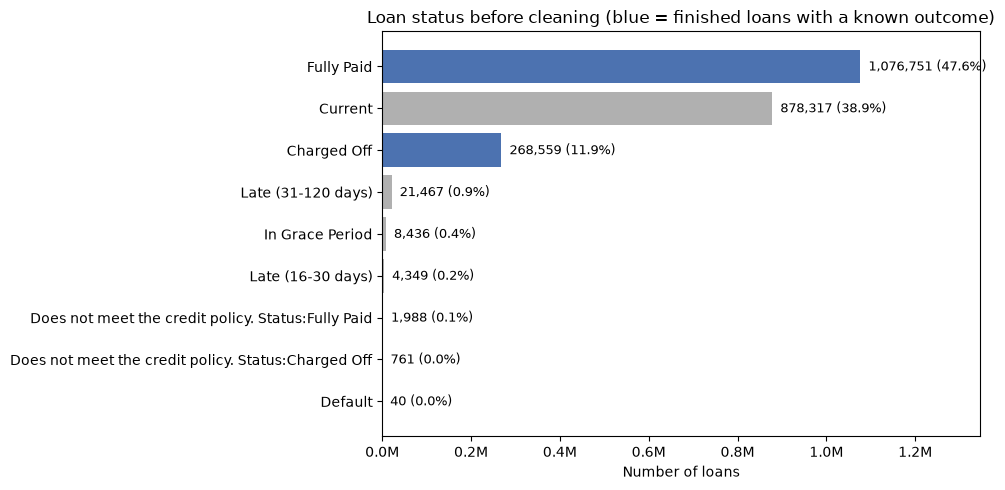

Finished loans (Fully Paid + Charged Off): 1345310
Charge-off rate among finished loans: 20.0%


In [104]:
# Stage 1, Step 3 - Visual 2: loan status distribution (raw data, before cleaning)
# Question: how did each loan end, and which loans have a known outcome?
status_counts = df['loan_status'].value_counts().sort_values()
status_pct = status_counts / status_counts.sum() * 100

# The two finished outcomes are highlighted; every other status has no final outcome yet
finished = ['Fully Paid', 'Charged Off']
colors = ['#4c72b0' if s in finished else '#b0b0b0' for s in status_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(status_counts.index, status_counts.values, color=colors)
for i, (count, pct) in enumerate(zip(status_counts.values, status_pct.values)):
    ax.text(count, i, '  {:,} ({:.1f}%)'.format(count, pct), va='center', fontsize=9)
ax.set_xlim(0, status_counts.max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, pos: '{:.1f}M'.format(v / 1e6)))
ax.set_xlabel('Number of loans')
ax.set_title('Loan status before cleaning (blue = finished loans with a known outcome)')
plt.tight_layout()
plt.show()

print('Finished loans (Fully Paid + Charged Off):', status_counts[finished].sum())
print('Charge-off rate among finished loans: {:.1f}%'.format(status_counts['Charged Off'] / status_counts[finished].sum() * 100))

In [105]:
# Stage 1, Step 4 - Define the target
# Keep only loans with a known final outcome; df stays untouched for the before/after comparison
from IPython.display import Markdown

finished = ['Fully Paid', 'Charged Off']
loans = df[df['loan_status'].isin(finished)].copy()

# Target column: 1 = Charged Off, 0 = Fully Paid
loans['charged_off'] = (loans['loan_status'] == 'Charged Off').astype(int)

# Check the result
display(Markdown('**Rows before and after keeping only finished loans (Fully Paid or Charged Off)**'))
print('Rows before (raw data, all statuses):', len(df))
print('Rows after (finished loans only):    ', len(loans))
print('Rows dropped:                        ', len(df) - len(loans))

display(Markdown('**Table 1. Target classes among the finished loans**<br>'
                 'charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. '
                 'Percentages are out of the finished loans.'))
classes = loans['charged_off'].value_counts().sort_index().to_frame('loans')
classes['share of finished loans (%)'] = (classes['loans'] / len(loans) * 100).round(1)
classes.index = ['0 = Fully Paid', '1 = Charged Off']
classes.index.name = 'charged_off'
display(classes)

# What was dropped, by status
display(Markdown('**Table 2. Loans removed by the filter, by loan status (raw data)**<br>'
                 'These rows are in the raw data but not in the finished loans. '
                 'NaN = the 33 junk rows that are not loans.'))
dropped = df.loc[~df['loan_status'].isin(finished), 'loan_status'].value_counts(dropna=False).to_frame('loans removed')
display(dropped)

**Rows before and after keeping only finished loans (Fully Paid or Charged Off)**

Rows before (raw data, all statuses): 2260701
Rows after (finished loans only):     1345310
Rows dropped:                         915391


**Table 1. Target classes among the finished loans**<br>charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the finished loans.

,loans,share of finished loans (%)
charged_off,,
0 = Fully Paid,1076751,80.0
1 = Charged Off,268559,20.0


**Table 2. Loans removed by the filter, by loan status (raw data)**<br>These rows are in the raw data but not in the finished loans. NaN = the 33 junk rows that are not loans.

,loans removed
loan_status,
Current,878317
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40
NaN,33


# Current

In [106]:
# Stage 1, Step 4 - Recheck missing rates on the finished loans
# Compare with the raw rates from Step 3 (missing_pct)
missing_after = loans.isna().mean().drop('charged_off') * 100
compare = pd.DataFrame({'raw_pct': missing_pct, 'finished_pct': missing_after})
compare['change'] = compare['finished_pct'] - compare['raw_pct']

# Kind of column, so the tables can say which columns moved
# Starts from family() in the Step 3 grouped chart, then splits its catch-all group further
def column_kind(col):
    kind = family(col)
    if kind != 'Other borrower and credit fields':
        return kind
    if col in ('out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int',
               'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
               'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'pymnt_plan', 'hardship_flag',
               'debt_settlement_flag'):
        return 'Payment history after the loan was issued'
    if col in ('id', 'url', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade',
               'sub_grade', 'issue_d', 'loan_status', 'purpose', 'title', 'initial_list_status', 'application_type',
               'disbursement_method', 'policy_code'):
        return 'Loan details'
    if col in ('emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'zip_code',
               'addr_state', 'dti'):
        return 'Borrower details'
    if col in ('delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
               'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq',
               'chargeoff_within_12_mths', 'delinq_amnt', 'pub_rec_bankruptcies', 'tax_liens'):
        return 'Core credit history'
    return 'Detailed credit-bureau fields'

compare['kind'] = [column_kind(col) for col in compare.index]

# Which missing-value band each column is in, before and after the filter
band_names = ['no missing values', 'under 5% missing', '5% to 30% missing', 'over 30% missing']
def band(pct):
    if pct == 0:
        return band_names[0]
    if pct < 5:
        return band_names[1]
    if pct <= 30:
        return band_names[2]
    return band_names[3]

compare['raw_band'] = compare['raw_pct'].map(band)
compare['finished_band'] = compare['finished_pct'].map(band)

# For each band: how many columns before and after, and which kinds of columns left it or joined it
left = {name: [] for name in band_names}
joined = {name: [] for name in band_names}
moved = compare[compare['raw_band'] != compare['finished_band']]
for (raw_band, finished_band), part in moved.groupby(['raw_band', 'finished_band']):
    for kind, n in part['kind'].value_counts().items():
        left[raw_band].append('{} ({}) moved to "{}"'.format(kind, n, finished_band))
        joined[finished_band].append('{} ({}) came from "{}"'.format(kind, n, raw_band))

band_table = pd.DataFrame({
    'raw data (number of columns)': compare['raw_band'].value_counts().reindex(band_names, fill_value=0),
    'finished loans (number of columns)': compare['finished_band'].value_counts().reindex(band_names, fill_value=0),
    'columns that left this band (kind and count)': ['; '.join(left[name]) or 'none' for name in band_names],
    'columns that joined this band (kind and count)': ['; '.join(joined[name]) or 'none' for name in band_names],
})
band_table.index.name = 'missing-value band'

display(Markdown('**Table 3. Number of columns in each missing-value band, before and after keeping only finished loans**<br>'
                 'Raw data = all real loans, any status (junk rows excluded). '
                 'Finished loans = Fully Paid or Charged Off only. '
                 'The last two fields say which kinds of columns changed band, how many, and where they went or came from.'))
with pd.option_context('display.max_colwidth', None):
    display(band_table)

# The 25 columns whose missing rate changed the most
# Descriptive names for display only; the data frame keeps its own column names
display(Markdown('**Table 4. The 25 columns whose missing rate changed most after keeping only finished loans**<br>'
                 'Each row is one column of the dataset. Change is in percentage points: '
                 'positive = emptier among finished loans, negative = fuller.'))
missing_labels = {'kind': 'kind of column',
                  'raw_pct': 'missing in raw data (%)',
                  'finished_pct': 'missing in finished loans (%)',
                  'change': 'change (percentage points)'}
order = compare['change'].abs().sort_values(ascending=False).index
display(compare.loc[order, ['kind', 'raw_pct', 'finished_pct', 'change']].head(25).round(1).rename(columns=missing_labels))

**Table 3. Number of columns in each missing-value band, before and after keeping only finished loans**<br>Raw data = all real loans, any status (junk rows excluded). Finished loans = Fully Paid or Charged Off only. The last two fields say which kinds of columns changed band, how many, and where they went or came from.

,raw data (number of columns),finished loans (number of columns),columns that left this band (kind and count),columns that joined this band (kind and count)
missing-value band,,,,
no missing values,38,46,none,"Core credit history (7) came from ""under 5% missing""; Borrower details (1) came from ""under 5% missing"""
under 5% missing,50,21,"Detailed credit-bureau fields (21) moved to ""5% to 30% missing""; Core credit history (7) moved to ""no missing values""; Borrower details (1) moved to ""no missing values""",none
5% to 30% missing,5,26,none,"Detailed credit-bureau fields (21) came from ""under 5% missing"""
over 30% missing,58,58,none,none


**Table 4. The 25 columns whose missing rate changed most after keeping only finished loans**<br>Each row is one column of the dataset. Change is in percentage points: positive = emptier among finished loans, negative = fuller.

,kind of column,missing in raw data (%),missing in finished loans (%),change (percentage points)
next_pymnt_d,Next payment date,59.5,100.0,40.5
total_cu_tl,Newer credit-bureau fields,38.3,60.0,21.7
inq_last_12m,Newer credit-bureau fields,38.3,60.0,21.7
open_acc_6m,Newer credit-bureau fields,38.3,60.0,21.7
total_bal_il,Newer credit-bureau fields,38.3,60.0,21.7
open_rv_12m,Newer credit-bureau fields,38.3,60.0,21.7
open_il_24m,Newer credit-bureau fields,38.3,60.0,21.7
open_act_il,Newer credit-bureau fields,38.3,60.0,21.7
open_rv_24m,Newer credit-bureau fields,38.3,60.0,21.7
inq_fi,Newer credit-bureau fields,38.3,60.0,21.7


In [107]:
# Stage 1, Step 4 - What the filter does year by year
# Recent loans that are already finished either defaulted early or were paid off early
from IPython.display import Markdown

all_year = df['issue_d'].str[-4:]
fin_year = loans['issue_d'].str[-4:]

by_year = pd.DataFrame({
    'all_loans': df.groupby(all_year)['loan_amnt'].count(),
    'finished': loans.groupby(fin_year)['loan_amnt'].count(),
    'charge_off_rate_pct': loans.groupby(fin_year)['charged_off'].mean() * 100,
    'fully_paid_rate_pct': (1 - loans.groupby(fin_year)['charged_off'].mean()) * 100,
})
by_year['finished_pct'] = by_year['finished'] / by_year['all_loans'] * 100
# Descriptive names for display only; the data frame keeps its own column names
labels = {'finished_pct': 'finished (%)',
          'charge_off_rate_pct': 'charged off (% out of finished)',
          'fully_paid_rate_pct': 'fully paid (% out of finished)'}
display(Markdown('**Table 5. Loans by issue year: how many are finished, and how the finished loans ended**<br>'
                 'all_loans = every loan issued that year, any status (raw data). '
                 'finished = loans that are Fully Paid or Charged Off. '
                 'finished (%) = finished loans out of all loans. '
                 'The last two columns are percentages of the finished loans only.'))
display(by_year[['all_loans', 'finished', 'finished_pct', 'charge_off_rate_pct', 'fully_paid_rate_pct']].round(1).rename(columns=labels))

# The same two rates split by loan term (36 or 60 months)
by_term = pd.DataFrame({
    'finished_pct': loans.groupby([fin_year, 'term']).size() / df.groupby([all_year, 'term']).size() * 100,
    'charge_off_rate_pct': loans.groupby([fin_year, 'term'])['charged_off'].mean() * 100,
    'fully_paid_rate_pct': (1 - loans.groupby([fin_year, 'term'])['charged_off'].mean()) * 100,
})
display(Markdown('**Table 6. Finished, charged-off and fully-paid rates by issue year and loan term (36 or 60 months)**<br>'
                 'finished (%) = finished loans out of all loans of that year and term (raw data). '
                 'Charged off and fully paid are percentages of the finished loans of that year and term. '
                 'NaN = no loans of that term were issued that year.'))
display(by_term.round(1).rename(columns=labels).unstack('term'))

**Table 5. Loans by issue year: how many are finished, and how the finished loans ended**<br>all_loans = every loan issued that year, any status (raw data). finished = loans that are Fully Paid or Charged Off. finished (%) = finished loans out of all loans. The last two columns are percentages of the finished loans only.

,all_loans,finished,finished (%),charged off (% out of finished),fully paid (% out of finished)
issue_d,,,,,
2007,603,251,41.6,17.9,82.1
2008,2393,1562,65.3,15.8,84.2
2009,5281,4716,89.3,12.6,87.4
2010,12537,11536,92.0,12.9,87.1
2011,21721,21721,100.0,15.2,84.8
2012,53367,53367,100.0,16.2,83.8
2013,134814,134804,100.0,15.6,84.4
2014,235629,223102,94.7,18.4,81.6
2015,421095,375545,89.2,20.2,79.8


**Table 6. Finished, charged-off and fully-paid rates by issue year and loan term (36 or 60 months)**<br>finished (%) = finished loans out of all loans of that year and term (raw data). Charged off and fully paid are percentages of the finished loans of that year and term. NaN = no loans of that term were issued that year.

finished (%)           charged off (% out of finished)            \
term       36 months 60 months                       36 months 60 months   
issue_d                                                                    
2007            41.6       NaN                            17.9       NaN   
2008            65.3       NaN                            15.8       NaN   
2009            89.3       NaN                            12.6       NaN   
2010            92.5      90.8                             9.9      21.0   
2011           100.0     100.0                            10.6      23.6   
2012           100.0     100.0                            13.6      27.7   
2013           100.0     100.0                            12.3      25.1   
2014           100.0      82.9                            13.7      31.1   
2015            99.9      67.1                            14.9      36.4   
2016            71.8      54.8                            19.8      36.4   
2017            40.1      33.1                            20.0      32.9   
2018            12.0      10.0                            13.2      22.6   

        fully paid (% out of finished)            
term                         36 months 60 months  
issue_d                                           
2007                              82.1       NaN  
2008                              84.2       NaN  
2009                              87.4       NaN  
2010                              90.1      79.0  
2011                              89.4      76.4  
2012                              86.4      72.3  
2013                              87.7      74.9  
2014                              86.3      68.9  
2015                              85.1      63.6  
2016                              80.2      63.6  
2017                              80.0      67.1  
2018                              86.8      77.4

In [108]:
# Stage 1, Step 4 - Keep only loans old enough to have finished
# Rule: a loan is kept only if its full term (36 or 60 months) had passed by the time the data was captured.
# Recent loans that are already finished ended early, so they are not a fair sample (see Tables 5 and 6).

# When the data was captured: the latest payment date anywhere in the raw data
snapshot = pd.to_datetime(df['last_pymnt_d'], format='%b-%Y').max()

# Months between each loan's issue date and the capture date, compared with its term
issue_date = pd.to_datetime(loans['issue_d'], format='%b-%Y')
term_months = loans['term'].str.strip().str[:2].astype(int)
months_elapsed = (snapshot.year - issue_date.dt.year) * 12 + (snapshot.month - issue_date.dt.month)
mature = months_elapsed >= term_months

# Summary by loan term, before the rows are removed
summary = pd.DataFrame({
    'finished loans before the rule': loans.groupby('term').size(),
    'loans kept': loans[mature].groupby('term').size(),
    'last issue month kept': issue_date[mature].groupby(loans['term']).max().dt.strftime('%b-%Y'),
    'charged off before the rule (%)': loans.groupby('term')['charged_off'].mean() * 100,
    'charged off after the rule (%)': loans[mature].groupby('term')['charged_off'].mean() * 100,
})
summary.insert(2, 'loans removed', summary['finished loans before the rule'] - summary['loans kept'])
rate_before = loans['charged_off'].mean() * 100
rows_before = len(loans)

# Apply the rule: loans now holds only loans old enough to have finished
loans = loans[mature].copy()

display(Markdown('**Rows before and after keeping only loans old enough to have finished**'))
print('Data captured (latest payment date):', snapshot.strftime('%B %Y'))
print('Finished loans before the rule:     ', rows_before)
print('Loans kept:                         ', len(loans))
print('Loans removed:                      ', rows_before - len(loans))
print('Charge-off rate before: {:.1f}%   after: {:.1f}%'.format(rate_before, loans['charged_off'].mean() * 100))

display(Markdown('**Table 7. Effect of the rule by loan term**<br>'
                 'A loan is kept only if its full term had passed by the capture date. '
                 'Charge-off percentages are out of the finished loans of that term.'))
display(summary.round(1))

display(Markdown('**Table 8. Target classes after the rule**<br>'
                 'charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the loans kept.'))
classes = loans['charged_off'].value_counts().sort_index().to_frame('loans')
classes['share of loans kept (%)'] = (classes['loans'] / len(loans) * 100).round(1)
classes.index = ['0 = Fully Paid', '1 = Charged Off']
classes.index.name = 'charged_off'
display(classes)

**Rows before and after keeping only loans old enough to have finished**

Data captured (latest payment date): March 2019
Finished loans before the rule:      1345310
Loans kept:                          776276
Loans removed:                       569034
Charge-off rate before: 20.0%   after: 15.2%


**Table 7. Effect of the rule by loan term**<br>A loan is kept only if its full term had passed by the capture date. Charge-off percentages are out of the finished loans of that term.

,finished loans before the rule,loans kept,loans removed,last issue month kept,charged off before the rule (%),charged off after the rule (%)
term,,,,,,
36 months,1020743,708368,312375,Mar-2016,16.0,14.2
60 months,324567,67908,256659,Mar-2014,32.4,25.3


**Table 8. Target classes after the rule**<br>charged_off is the target column: 0 = Fully Paid, 1 = Charged Off. Percentages are out of the loans kept.

,loans,share of loans kept (%)
charged_off,,
0 = Fully Paid,658666,84.8
1 = Charged Off,117610,15.2


In [109]:
# Stage 1, Step 5 - Free-text and location columns (decision D6)
# emp_title and title are hand-typed text; zip_code and addr_state are location codes.
# Decision: drop emp_title and title, keep zip_code and addr_state.
text_decisions = {
    'emp_title': 'drop: hand-typed job titles, almost all unique',
    'title': 'drop: near-copy of purpose plus hand-typed text',
    'zip_code': 'keep: three-digit ZIP area, possible map',
    'addr_state': 'keep: clean two-letter state code',
}

# Evidence for the decision, taken before anything is dropped
if 'emp_title' in loans.columns:
    rows = {}
    for col in text_decisions:
        counts = loans[col].value_counts()
        rows[col] = {
            'distinct values': len(counts),
            'values that appear once': int((counts == 1).sum()),
            'missing (%)': round(loans[col].isna().mean() * 100, 1),
            'most common value': '{} ({:,})'.format(counts.index[0], counts.iloc[0]),
            'decision': text_decisions[col],
        }
    text_summary = pd.DataFrame(rows).T
    text_summary.index.name = 'column'

display(Markdown('**Table 9. Free-text and location columns: what they hold and what we do with them**<br>'
                 'Measured on the loans kept after Step 4. A column with a huge number of distinct values, '
                 'most of them appearing once, cannot be used as a category.'))
with pd.option_context('display.max_colwidth', None):
    display(text_summary)

# Drop the two free-text columns; dropped keeps a record of every column removed in Step 5 and why
dropped = {}
for col in ('emp_title', 'title'):
    dropped[col] = text_decisions[col].replace('drop: ', '')
print('Columns before:', loans.shape[1])
loans = loans.drop(columns=list(dropped), errors='ignore')
print('Columns after: ', loans.shape[1])
print('Dropped:', list(dropped))

**Table 9. Free-text and location columns: what they hold and what we do with them**<br>Measured on the loans kept after Step 4. A column with a huge number of distinct values, most of them appearing once, cannot be used as a category.

,distinct values,values that appear once,missing (%),most common value,decision
column,,,,,
emp_title,272023,224000,6.6,"Teacher (11,258)","drop: hand-typed job titles, almost all unique"
title,61678,52638,0.9,"Debt consolidation (330,469)",drop: near-copy of purpose plus hand-typed text
zip_code,924,32,0.0,"945xx (8,859)","keep: three-digit ZIP area, possible map"
addr_state,51,0,0.0,"CA (118,049)",keep: clean two-letter state code


Columns before: 152
Columns after:  150
Dropped: ['emp_title', 'title']


In [110]:
# Stage 1, Step 5 - Combined income and debt-to-income for joint applications (decision D3)
# A joint application was judged on the joint figures, so use those for joint loans and the individual ones otherwise.
# This has to run before the joint columns are dropped for being mostly empty.
if 'annual_inc_joint' in loans.columns:
    is_joint = loans['application_type'] == 'Joint App'
    use_joint_inc = is_joint & loans['annual_inc_joint'].notna()
    use_joint_dti = is_joint & loans['dti_joint'].notna()
    loans['annual_inc_combined'] = loans['annual_inc'].where(~use_joint_inc, loans['annual_inc_joint'])
    loans['dti_combined'] = loans['dti'].where(~use_joint_dti, loans['dti_joint'])

    joint_summary = pd.DataFrame(
        {'loans': [len(loans), int(is_joint.sum()), int(use_joint_inc.sum()), int(use_joint_dti.sum())]},
        index=['all loans kept', 'joint applications', 'income taken from the joint figure', 'dti taken from the joint figure'])
    joint_summary['share of loans kept (%)'] = (joint_summary['loans'] / len(loans) * 100).round(2)

    joint_check = pd.DataFrame({
        'individual figures': [int((loans['annual_inc'] == 0).sum()), int(loans['dti'].isna().sum()), int((loans['dti'] > 100).sum())],
        'combined figures': [int((loans['annual_inc_combined'] == 0).sum()), int(loans['dti_combined'].isna().sum()), int((loans['dti_combined'] > 100).sum())],
    }, index=['loans with an income of zero', 'loans with dti missing', 'loans with dti above 100'])

display(Markdown('**Table 10. Joint applications among the loans kept, and where the joint figures are used**<br>'
                 'annual_inc_combined and dti_combined take the joint value for joint applications and the individual value otherwise.'))
display(joint_summary)
display(Markdown('**Table 11. The problem values before and after combining**<br>'
                 'Number of loans with each problem, using the individual figures and using the combined figures.'))
display(joint_check)

**Table 10. Joint applications among the loans kept, and where the joint figures are used**<br>annual_inc_combined and dti_combined take the joint value for joint applications and the individual value otherwise.

,loans,share of loans kept (%)
all loans kept,776276,100.00
joint applications,1627,0.21
income taken from the joint figure,1627,0.21
dti taken from the joint figure,1624,0.21


**Table 11. The problem values before and after combining**<br>Number of loans with each problem, using the individual figures and using the combined figures.

,individual figures,combined figures
loans with an income of zero,8,0
loans with dti missing,9,0
loans with dti above 100,22,0


In [111]:
# Stage 1, Step 5 - Drop columns that are more than 30% empty (decision D7)
# Missing rates are recalculated on the loans kept, because they changed again after the loan-age rule.
# This includes the five "months since last delinquency or record" columns.
missing_now = loans.isna().mean() * 100
over30 = missing_now[missing_now > 30].sort_values(ascending=False)
columns_before = loans.shape[1]

if len(over30) > 0:
    over30_table = pd.DataFrame({'kind': [column_kind(col) for col in over30.index], 'missing': over30})
    over30_summary = over30_table.groupby('kind')['missing'].agg(['count', 'min', 'max']).sort_values('max', ascending=False).round(1)
    over30_summary.columns = ['columns dropped', 'lowest missing rate (%)', 'highest missing rate (%)']
    over30_summary.index.name = 'kind of column'
    for col, pct in over30.items():
        dropped[col] = 'more than 30% empty ({:.1f}%)'.format(pct)
    loans = loans.drop(columns=list(over30.index))

display(Markdown('**Table 12. Columns dropped for being more than 30% empty, by kind of column**<br>'
                 'Missing rates are measured on the loans kept after Step 4.'))
display(over30_summary)
print('Columns before:', columns_before)
print('Columns after: ', loans.shape[1])
print('Dropped in this cell:', columns_before - loans.shape[1])

**Table 12. Columns dropped for being more than 30% empty, by kind of column**<br>Missing rates are measured on the loans kept after Step 4.

,columns dropped,lowest missing rate (%),highest missing rate (%)
kind of column,,,
Empty identifier and optional free text,2,84.1,100.0
Next payment date,1,100.0,100.0
Second applicant and joint fields,16,99.8,100.0
Hardship plan fields,14,99.8,99.8
Debt settlement fields,6,98.3,98.3
Newer credit-bureau fields,14,86.5,88.4
Months since last delinquency or record,5,51.3,84.2


Columns before: 152
Columns after:  94
Dropped in this cell: 58


In [112]:
# Stage 1, Step 5 - Drop leakage columns (decision D8)
# These were recorded after the loan was issued, so they would not be known when deciding on an application.
leakage = {
    'out_prncp': 'principal still owed', 'out_prncp_inv': 'principal still owed to investors',
    'total_pymnt': 'payments received', 'total_pymnt_inv': 'payments received by investors',
    'total_rec_prncp': 'principal repaid', 'total_rec_int': 'interest repaid', 'total_rec_late_fee': 'late fees paid',
    'recoveries': 'money recovered after charge-off', 'collection_recovery_fee': 'collection fee after charge-off',
    'last_pymnt_d': 'date of last payment', 'last_pymnt_amnt': 'amount of last payment',
    'next_pymnt_d': 'date of next payment', 'last_credit_pull_d': 'date of latest credit check',
    'last_fico_range_high': 'latest FICO score', 'last_fico_range_low': 'latest FICO score',
    'pymnt_plan': 'payment plan set up after issue', 'hardship_flag': 'hardship plan after issue',
    'debt_settlement_flag': 'debt settlement after issue',
}
leak_present = [col for col in leakage if col in loans.columns]
columns_before = loans.shape[1]

# Evidence, taken before the columns are dropped: these columns give the outcome away
if 'recoveries' in loans.columns:
    by_outcome = loans.groupby('charged_off')
    leak_evidence = pd.DataFrame({
        'loans with money recovered after charge-off (%)': by_outcome['recoveries'].apply(lambda s: (s > 0).mean() * 100),
        'average share of the loan amount repaid (%)': (loans['total_rec_prncp'] / loans['loan_amnt']).groupby(loans['charged_off']).mean() * 100,
        'average latest FICO score (after issue)': by_outcome['last_fico_range_high'].mean(),
        'average FICO score at application': by_outcome['fico_range_high'].mean(),
    }).round(1)
    leak_evidence.index = ['0 = Fully Paid', '1 = Charged Off']
    leak_evidence.index.name = 'charged_off'

for col in leak_present:
    dropped[col] = 'leakage: ' + leakage[col] + ', recorded after the loan was issued'
loans = loans.drop(columns=leak_present)

display(Markdown('**Table 13. Why these columns are leakage: they differ by outcome because they were recorded after it**<br>'
                 'The FICO score at application is shown for contrast; it was known before the loan was issued and is kept.'))
with pd.option_context('display.max_colwidth', None):
    display(leak_evidence.T)
print('Columns before:', columns_before)
print('Columns after: ', loans.shape[1])
print('Dropped in this cell:', leak_present)
print('Total columns dropped so far in Step 5:', len(dropped))

**Table 13. Why these columns are leakage: they differ by outcome because they were recorded after it**<br>The FICO score at application is shown for contrast; it was known before the loan was issued and is kept.

charged_off,0 = Fully Paid,1 = Charged Off
loans with money recovered after charge-off (%),0.0,78.7
average share of the loan amount repaid (%),99.9,39.8
average latest FICO score (after issue),700.9,573.9
average FICO score at application,701.1,690.7


Columns before: 94
Columns after:  77
Dropped in this cell: ['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'pymnt_plan', 'hardship_flag', 'debt_settlement_flag']
Total columns dropped so far in Step 5: 77


In [113]:
# Stage 1, Step 5 - Keep a copy of the numeric columns before their missing values are filled
# The next cell overwrites the missing values, so the real values are saved here for the before/after chart.
cols_to_fill = [col for col in loans.select_dtypes(include='number').columns
                if loans[col].isna().any() and col != 'dti']
if len(cols_to_fill) > 0:
    before_fill = loans[cols_to_fill].copy()
    print('Saved the real values of', len(cols_to_fill), 'columns (their missing values are still blank).')
elif 'before_fill' in globals():
    print('The columns are already filled; keeping the copy saved earlier.')
else:
    print('The columns are already filled and no copy exists.')
    print('Re-run the notebook from "Define the target" so this cell runs before the filling cell.')

Saved the real values of 39 columns (their missing values are still blank).


In [114]:
# Stage 1, Step 5 - Impute missing values in numeric columns (decision D9)
# Rule: fill a column with its MEDIAN if it is skewed, and with its MEAN if it is roughly symmetric.
#   - Roughly symmetric means a skew between -0.5 and 0.5.
#   - In a skewed column the mean is pulled toward the long tail, so the median is the more typical value.
#   - In a symmetric column the mean and the median are almost the same, and the mean uses every value.
# Skew, median and mean are all measured on the real (non-missing) values, before anything is filled.
# Not handled here: emp_length (text), and dti (the individual figure, replaced by dti_combined).
numeric_missing = [col for col in loans.select_dtypes(include='number').columns
                   if loans[col].isna().any() and col != 'dti']

if len(numeric_missing) > 0:
    # Mark the loans whose detailed credit-bureau fields were never collected (issued before the fields existed),
    # so real values can be told apart from filled ones. Keep these loans out of any chart of those fields.
    loans['bureau_not_collected'] = loans['tot_cur_bal'].isna().astype(int)

    rows = {}
    for col in numeric_missing:
        skew = loans[col].skew()
        symmetric = abs(skew) <= 0.5
        fill_value = loans[col].mean() if symmetric else loans[col].median()
        rows[col] = {
            'missing before (%)': loans[col].isna().mean() * 100,
            'loans filled': int(loans[col].isna().sum()),
            'skew': skew,
            'shape': 'roughly symmetric' if symmetric else 'skewed',
            'filled with': 'mean' if symmetric else 'median',
            'fill value': fill_value,
        }
        loans[col] = loans[col].fillna(fill_value)
    impute_table = pd.DataFrame(rows).T.sort_values('missing before (%)', ascending=False)
    impute_table.index.name = 'column'
    for col_name in ('missing before (%)', 'skew', 'fill value'):
        impute_table[col_name] = impute_table[col_name].astype(float).round(2)

display(Markdown('**Table 14. Numeric columns with missing values: how each one was filled**<br>'
                 'Skewed columns (skew outside -0.5 to 0.5) are filled with the median; '
                 'roughly symmetric columns are filled with the mean. Measured on the loans kept, before filling.'))
display(impute_table)
print('Columns filled with the median:', int((impute_table['filled with'] == 'median').sum()))
print('Columns filled with the mean:  ', int((impute_table['filled with'] == 'mean').sum()),
      '->', list(impute_table.index[impute_table['filled with'] == 'mean']))
print('Loans marked bureau_not_collected:', int(loans['bureau_not_collected'].sum()))
still_missing = loans.isna().sum()
print('Columns that still have missing values:', still_missing[still_missing > 0].to_dict())

**Table 14. Numeric columns with missing values: how each one was filled**<br>Skewed columns (skew outside -0.5 to 0.5) are filled with the median; roughly symmetric columns are filled with the mean. Measured on the loans kept, before filling.

,missing before (%),loans filled,skew,shape,filled with,fill value
column,,,,,,
mths_since_recent_inq,16.07,124713,0.92,skewed,median,5.00
num_tl_120dpd_2m,12.06,93636,49.00,skewed,median,0.00
mo_sin_old_il_acct,11.93,92584,0.36,roughly symmetric,mean,125.47
pct_tl_nvr_dlq,8.72,67680,-2.14,skewed,median,97.90
avg_cur_bal,8.70,67538,4.33,skewed,median,6653.00
mo_sin_old_rev_tl_op,8.70,67528,1.05,skewed,median,165.00
num_rev_accts,8.70,67528,1.23,skewed,median,13.00
mo_sin_rcnt_rev_tl_op,8.70,67528,3.30,skewed,median,8.00
num_actv_rev_tl,8.70,67527,1.48,skewed,median,5.00


Columns filled with the median: 35
Columns filled with the mean:   4 -> ['mo_sin_old_il_acct', 'bc_util', 'percent_bc_gt_75', 'revol_util']
Loans marked bureau_not_collected: 67527
Columns that still have missing values: {'emp_length': 44755, 'dti': 9}


**Before and after filling: the mean-filled columns and 8 representative median-filled columns**<br>Blue = real values. Red outline = the same column after filling; it rises above the blue only at the fill value, and that jump is the filled loans, not real borrowers. Where the dashed mean line sits away from the solid median line, the column is skewed and the median is the more typical value. Each panel shows the 1st to 99th percentile of the real values.

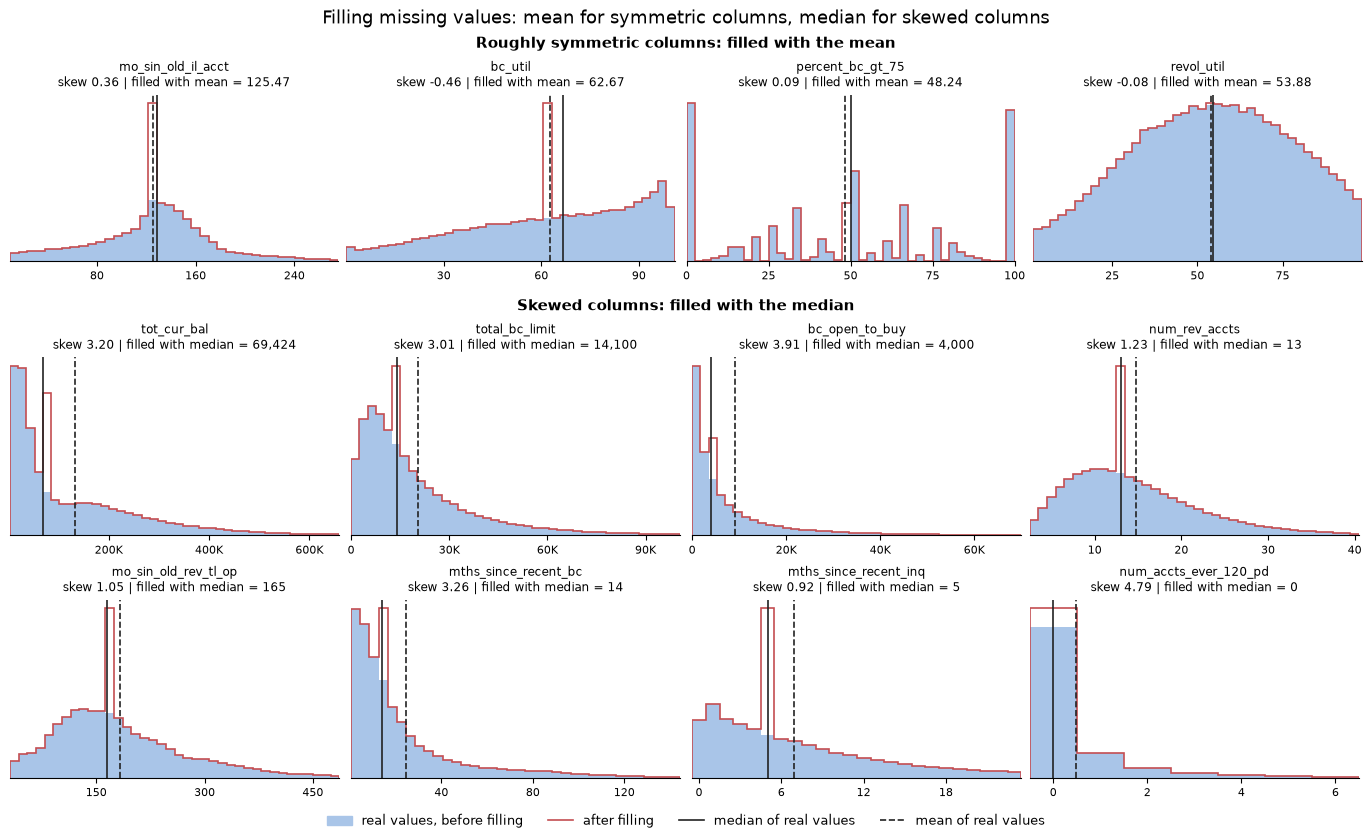

**Before and after filling: all 39 filled columns**<br>Same reading as above. Columns whose panel is a single bar are almost all zeros.

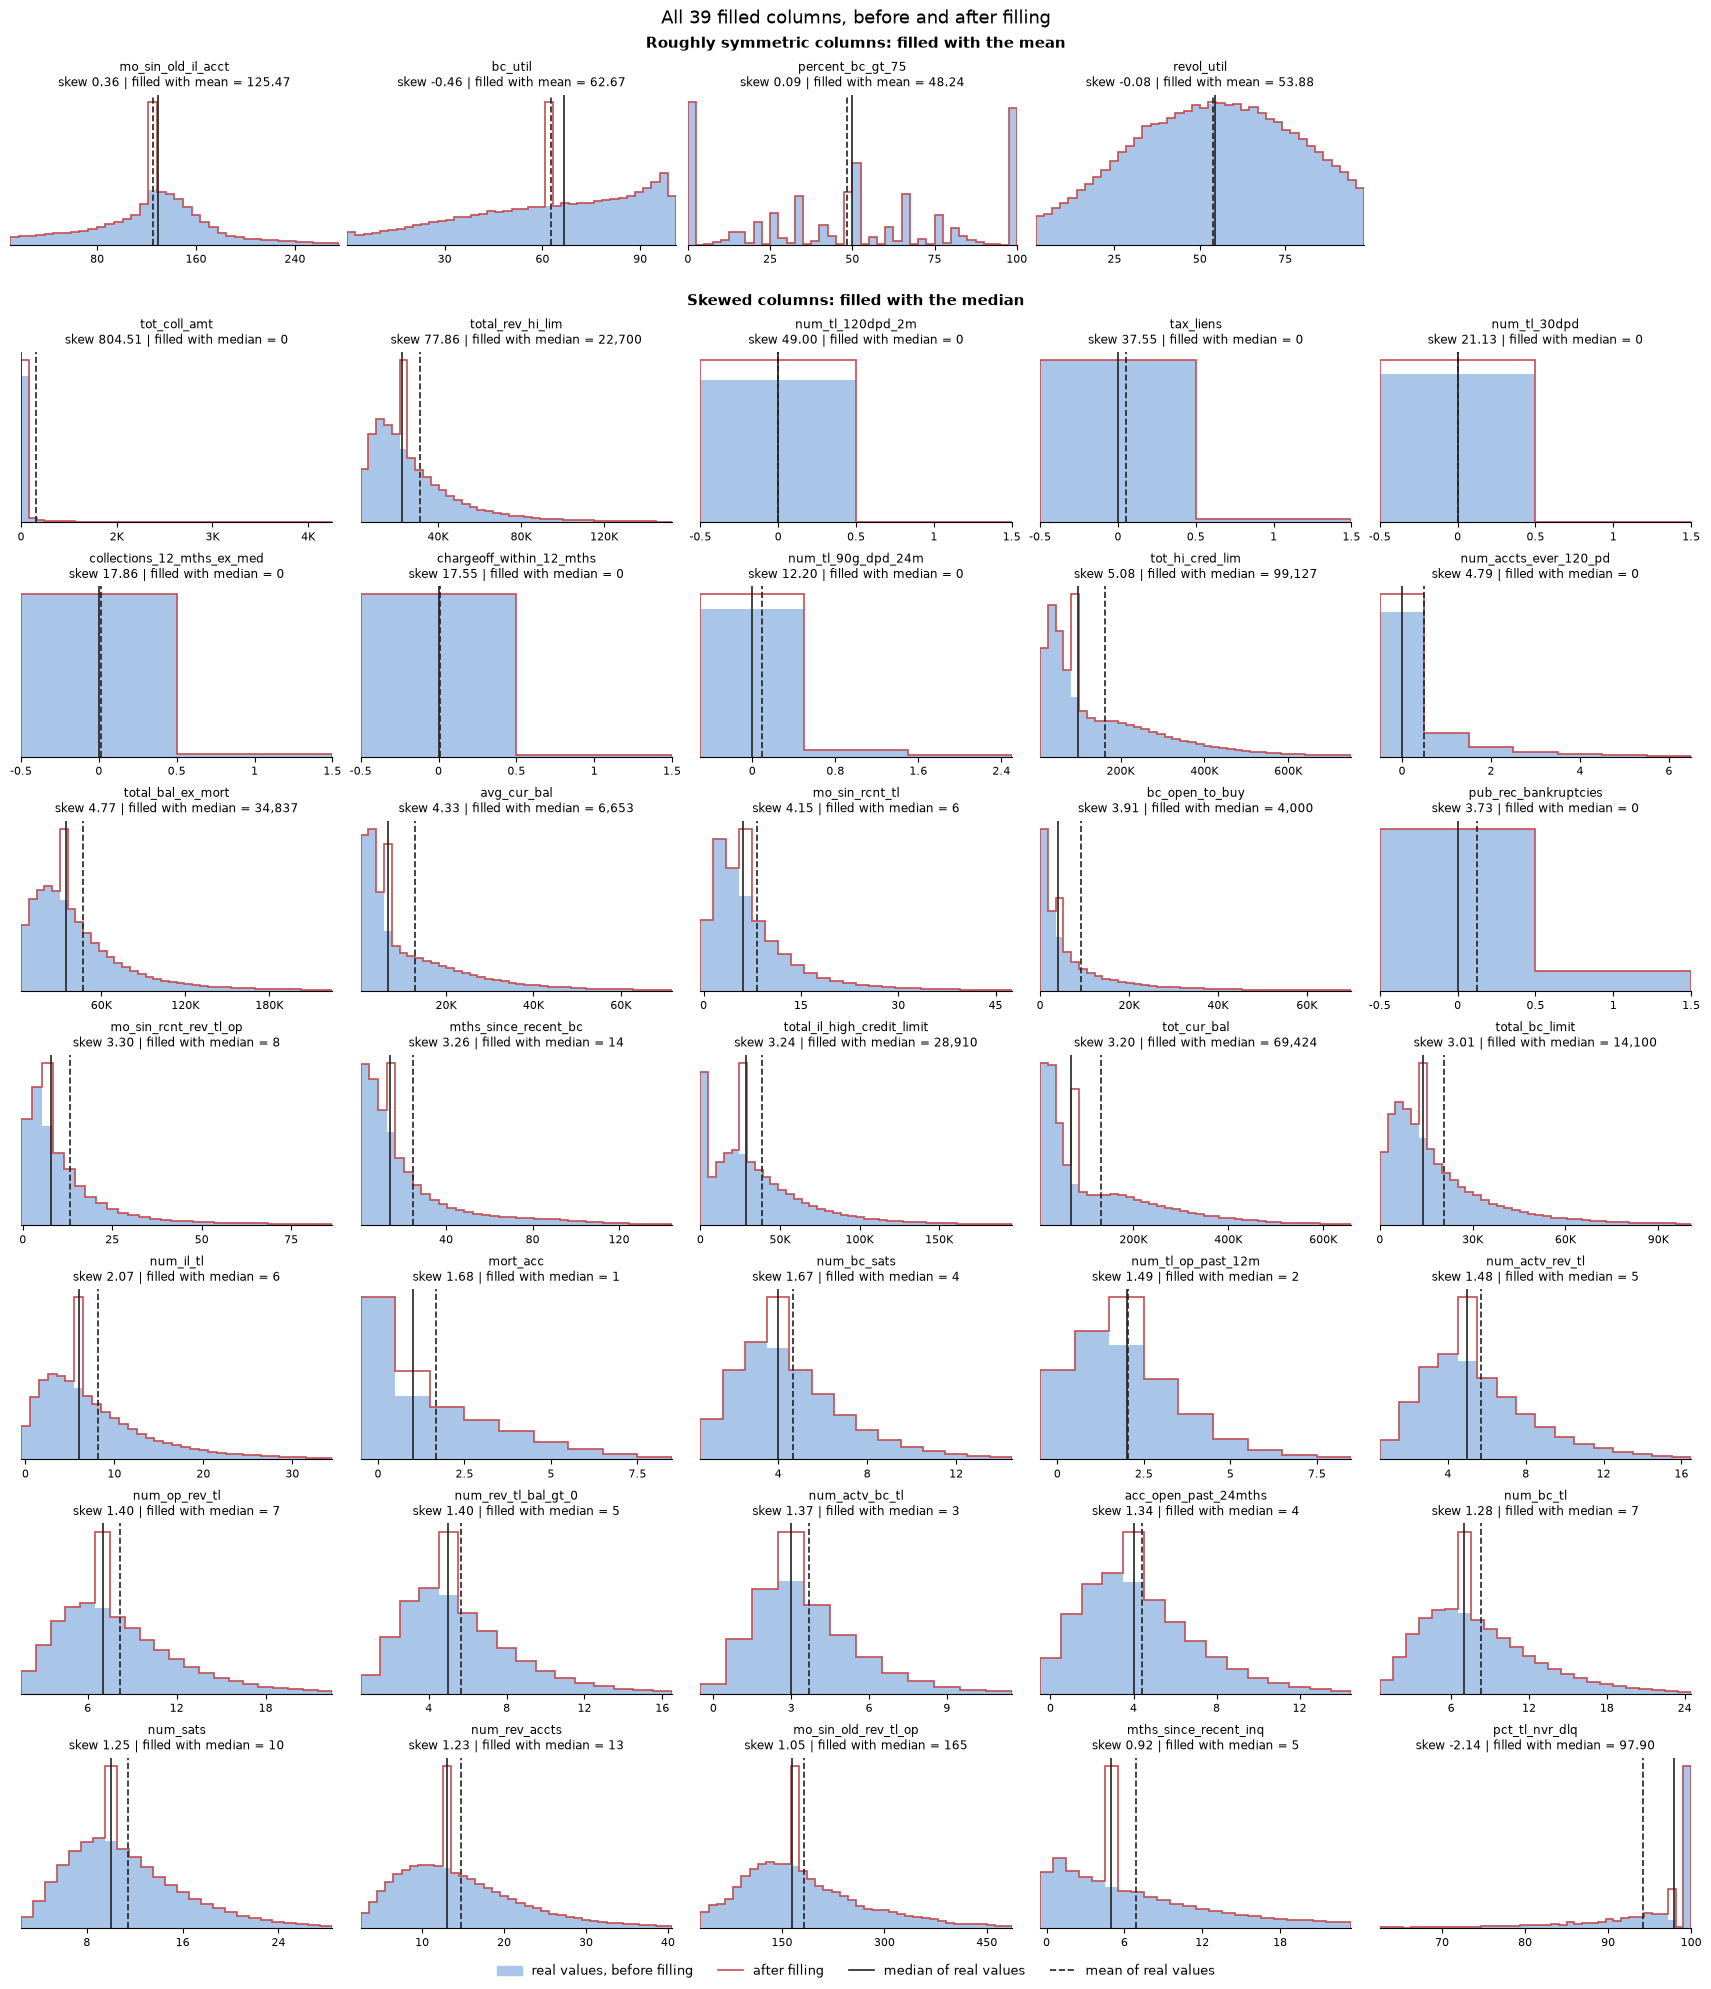

In [115]:
# # Stage 1, Step 5 - Before and after filling: distributions of the filled columns (decision D9)
# # Question: what did filling do to each column, and why the mean for some and the median for others?
# # Each panel shows the real values (blue), the same column after filling (red outline),
# # and the median (solid line) and mean (dashed line) of the real values.
# # Panels cover the 1st to 99th percentile of the real values, so long tails do not flatten the picture.
# from matplotlib.patches import Patch
# from matplotlib.lines import Line2D
# from matplotlib.ticker import FuncFormatter, MaxNLocator

# if 'before_fill' not in globals() or not before_fill.isna().any().any():
#     raise RuntimeError('No copy of the real values. Re-run the notebook from "Define the target" '
#                        'so the copy cell runs before the filling cell.')

# def short_number(value, pos=None):
#     if abs(value) >= 1e6:
#         return '{:.1f}M'.format(value / 1e6)
#     if abs(value) >= 1e3:
#         return '{:.0f}K'.format(value / 1e3)
#     return '{:g}'.format(value)

# def fill_text(value):
#     if abs(value) >= 1000 or value == round(value):
#         return '{:,.0f}'.format(value)
#     return '{:,.2f}'.format(value)

# def panel_numbers(col):
#     real = before_fill[col].dropna()
#     low, high = real.quantile(0.01), real.quantile(0.99)
#     if high <= low:
#         high = low + 1
#     if (real % 1 == 0).all():
#         # whole-number column: bin edges sit between whole numbers, so no bar is split
#         width = max(1, int(np.ceil((high - low + 1) / 40)))
#         edges = np.arange(low - 0.5, high + 0.5 + width, width)
#     else:
#         edges = np.linspace(low, high, 41)
#     return {'edges': edges,
#             'before': np.histogram(real, bins=edges)[0],
#             'after': np.histogram(loans[col], bins=edges)[0],
#             'mean': real.mean(), 'median': real.median()}

# panel_data = {col: panel_numbers(col) for col in impute_table.index}

# def draw_panel(ax, col):
#     p = panel_data[col]
#     row = impute_table.loc[col]
#     ax.stairs(p['before'], p['edges'], fill=True, color='#a9c5e8')
#     ax.stairs(p['after'], p['edges'], color='#c44e52', linewidth=1.2)
#     ax.axvline(p['median'], color='#222222', linewidth=1.2)
#     ax.axvline(p['mean'], color='#222222', linewidth=1.2, linestyle='--')
#     ax.set_title('{}\nskew {:.2f} | filled with {} = {}'.format(col, row['skew'], row['filled with'], fill_text(row['fill value'])),
#                  fontsize=8.5)
#     ax.set_xlim(p['edges'][0], p['edges'][-1])
#     ax.set_yticks([])
#     ax.xaxis.set_major_locator(MaxNLocator(4))
#     ax.xaxis.set_major_formatter(FuncFormatter(short_number))
#     ax.tick_params(axis='x', labelsize=8)
#     for side in ('top', 'right', 'left'):
#         ax.spines[side].set_visible(False)

# def grouped_figure(mean_cols, median_cols, ncols, title):
#     median_rows = int(np.ceil(len(median_cols) / ncols))
#     fig = plt.figure(figsize=(3.4 * ncols, 2.3 * (1 + median_rows) + 1.4), layout='constrained')
#     top, bottom = fig.subfigures(2, 1, height_ratios=[1, median_rows])
#     top.suptitle('Roughly symmetric columns: filled with the mean', fontsize=11, fontweight='bold')
#     bottom.suptitle('Skewed columns: filled with the median', fontsize=11, fontweight='bold')
#     for subfig, cols, nrows in ((top, mean_cols, 1), (bottom, median_cols, median_rows)):
#         axes = np.atleast_1d(subfig.subplots(nrows, ncols)).ravel()
#         for ax, col in zip(axes, cols):
#             draw_panel(ax, col)
#         for ax in axes[len(cols):]:
#             ax.set_visible(False)
#     handles = [Patch(color='#a9c5e8', label='real values, before filling'),
#                Line2D([0], [0], color='#c44e52', linewidth=1.2, label='after filling'),
#                Line2D([0], [0], color='#222222', linewidth=1.2, label='median of real values'),
#                Line2D([0], [0], color='#222222', linewidth=1.2, linestyle='--', label='mean of real values')]
#     fig.legend(handles=handles, loc='outside lower center', ncols=4, frameon=False, fontsize=9)
#     fig.suptitle(title, fontsize=13)
#     return fig

# mean_cols = list(impute_table.index[impute_table['filled with'] == 'mean'])
# median_cols = list(impute_table[impute_table['filled with'] == 'median'].sort_values('skew', ascending=False).index)

# # Slide version: the mean-filled columns and 8 representative median-filled columns
# # (a balance, a credit limit, available credit, an account count, an account age, two "months since" fields, a mostly-zero count)
# representative = ['tot_cur_bal', 'total_bc_limit', 'bc_open_to_buy', 'num_rev_accts',
#                   'mo_sin_old_rev_tl_op', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd']
# representative = [col for col in representative if col in median_cols]

# display(Markdown('**Before and after filling: the mean-filled columns and 8 representative median-filled columns**<br>'
#                  'Blue = real values. Red outline = the same column after filling; it rises above the blue only at the fill value, '
#                  'and that jump is the filled loans, not real borrowers. '
#                  'Where the dashed mean line sits away from the solid median line, the column is skewed and the median is the more typical value. '
#                  'Each panel shows the 1st to 99th percentile of the real values.'))
# grouped_figure(mean_cols, representative, 4, 'Filling missing values: mean for symmetric columns, median for skewed columns')
# plt.show()

# # Full version: every filled column, skewed columns ordered from most to least skewed
# display(Markdown('**Before and after filling: all {} filled columns**<br>'
#                  'Same reading as above. Columns whose panel is a single bar are almost all zeros.'.format(len(impute_table))))
# grouped_figure(mean_cols, median_cols, 5, 'All {} filled columns, before and after filling'.format(len(impute_table)))
# plt.show()